In [88]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as sk
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score,cross_val_predict
from sklearn.model_selection import cross_validate
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.over_sampling import SMOTENC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import shap
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, auc,precision_score, recall_score, f1_score
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import precision_recall_curve

In [4]:
df=pd.read_csv("paysim dataset.csv")
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [5]:
print(df.info())
print(df.columns)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB
None
Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='object')


In [6]:
df.isna().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [7]:
df["isFraud"].value_counts(normalize=True)

isFraud
0    0.998709
1    0.001291
Name: proportion, dtype: float64

In [8]:
df.dtypes

step                int64
type               object
amount            float64
nameOrig           object
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest           object
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object

In [9]:
X = df.drop(columns=["isFraud"])
y = df["isFraud"]
categorical_features = X.select_dtypes(include=["object"]).columns
numerical_features = X.select_dtypes(include=["int64", "float64"]).columns
coll_to_drop = ["nameOrig", "nameDest", "isFlaggedFraud"]

In [10]:
print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)
print("le nombre de variable dans chaque groupe est:", len(categorical_features), len(numerical_features))

Categorical features: Index(['type', 'nameOrig', 'nameDest'], dtype='object')
Numerical features: Index(['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest',
       'newbalanceDest', 'isFlaggedFraud'],
      dtype='object')
le nombre de variable dans chaque groupe est: 3 7


In [11]:
df["type"].value_counts()

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

In [12]:
df["type"].value_counts(normalize=True)

type
CASH_OUT    0.351663
PAYMENT     0.338146
CASH_IN     0.219923
TRANSFER    0.083756
DEBIT       0.006512
Name: proportion, dtype: float64

In [13]:
df.groupby("type")["isFraud"].sum()

type
CASH_IN        0
CASH_OUT    4116
DEBIT          0
PAYMENT        0
TRANSFER    4097
Name: isFraud, dtype: int64

In [14]:
df.groupby("type")["isFraud"].mean()

type
CASH_IN     0.000000
CASH_OUT    0.001840
DEBIT       0.000000
PAYMENT     0.000000
TRANSFER    0.007688
Name: isFraud, dtype: float64

In [15]:
df[numerical_features].describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00


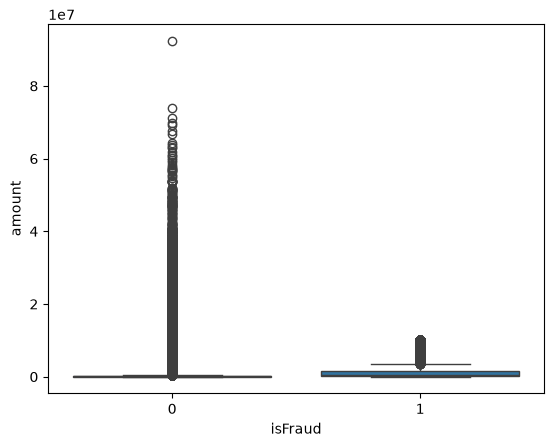

In [16]:
sns.boxplot(x="isFraud", y="amount", data=df)
plt.show()

In [17]:
df.groupby("isFraud")[numerical_features].mean()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFlaggedFraud
isFraud,,,,,,,
0,243.235663,1.781970e+05,8.328287e+05,855970.228109,1.101421e+06,1.224926e+06,0.000000
1,368.413856,1.467967e+06,1.649668e+06,192392.631836,5.442496e+05,1.279708e+06,0.001948


In [18]:
numerical_features_v1 = numerical_features.tolist() + ["isFraud"]

correlation = df[numerical_features_v1].corr()

correlation["isFraud"].sort_values(ascending=False)

isFraud           1.000000
amount            0.076688
isFlaggedFraud    0.044109
step              0.031578
oldbalanceOrg     0.010154
newbalanceDest    0.000535
oldbalanceDest   -0.005885
newbalanceOrig   -0.008148
Name: isFraud, dtype: float64

In [19]:
df["isFlaggedFraud"].value_counts()

isFlaggedFraud
0    6362604
1         16
Name: count, dtype: int64

In [20]:
pd.crosstab(df["isFlaggedFraud"], df["isFraud"])

isFraud,0,1
isFlaggedFraud,,
0,6354407,8197
1,0,16


In [21]:
pd.crosstab(df["type"], df["isFraud"])


isFraud,0,1
type,,
CASH_IN,1399284,0
CASH_OUT,2233384,4116
DEBIT,41432,0
PAYMENT,2151495,0
TRANSFER,528812,4097


In [22]:
X=X.drop(columns=coll_to_drop)
categorical_features = X.select_dtypes(include=["object"]).columns
numerical_features = X.select_dtypes(include=["int64", "float64"]).columns

In [23]:
print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Categorical features: Index(['type'], dtype='object')
Numerical features: Index(['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest',
       'newbalanceDest'],
      dtype='object')


In [24]:
print(X.shape)
print(y.shape)

(6362620, 7)
(6362620,)


In [25]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [26]:
print(X_train.shape)
print(X_test.shape)
print(y_train.value_counts())
print(y_test.value_counts())

(5090096, 7)
(1272524, 7)
isFraud
0    5083526
1       6570
Name: count, dtype: int64
isFraud
0    1270881
1       1643
Name: count, dtype: int64


In [27]:
preprocessor = ColumnTransformer(
    transformers=[
        ("scaler", StandardScaler(), numerical_features),
        ("encoder", OneHotEncoder(drop='first'), categorical_features)
    ]
)

In [28]:
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

In [29]:
print(X_train_transformed.shape)
print(X_test_transformed.shape)
print(type(X_train_transformed))

(5090096, 10)
(1272524, 10)
<class 'numpy.ndarray'>


In [30]:
pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression())
    ]
)

In [31]:
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['step','type','amount',...,'newbalanceOrig','oldbalanceDest', 'newbalanceDest']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('scaler', ...), ('encoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='p

In [32]:
y_pred = pipeline.predict(X_test)

In [33]:
print(y_pred[:20])

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [34]:
print("Fraudes prédites :", (y_pred == 1).sum())
print("Transactions normales prédites :", (y_pred == 0).sum())

Fraudes prédites : 724
Transactions normales prédites : 1271800


In [35]:
print("Fraudes réelles :", y_test.sum())

Fraudes réelles : 1643


In [36]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print(cm)

[[1270829      52]
 [    971     672]]


In [37]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.93      0.41      0.57      1643

    accuracy                           1.00   1272524
   macro avg       0.96      0.70      0.78   1272524
weighted avg       1.00      1.00      1.00   1272524



In [38]:
pipeline_balanced = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(class_weight="balanced"))
    ]
)

In [39]:
pipeline_balanced.fit(X_train, y_train)
y_pred_balanced = pipeline_balanced.predict(X_test)
print(classification_report(y_test, y_pred_balanced))

              precision    recall  f1-score   support

           0       1.00      0.95      0.97   1270881
           1       0.02      0.96      0.05      1643

    accuracy                           0.95   1272524
   macro avg       0.51      0.95      0.51   1272524
weighted avg       1.00      0.95      0.97   1272524



In [40]:
cm = confusion_matrix(y_test, y_pred_balanced)
print(cm)

[[1205997   64884]
 [     66    1577]]


In [41]:
y_proba = pipeline.predict_proba(X_test)

print(y_proba[:10])

[[9.99359361e-01 6.40638992e-04]
 [1.00000000e+00 4.00888024e-11]
 [1.00000000e+00 1.27508477e-18]
 [9.99922120e-01 7.78799151e-05]
 [9.99446875e-01 5.53124515e-04]
 [9.99792571e-01 2.07429048e-04]
 [9.99796710e-01 2.03289542e-04]
 [9.99278163e-01 7.21837013e-04]
 [1.00000000e+00 7.38754923e-13]
 [1.00000000e+00 7.95662103e-20]]


In [44]:
fraud_proba = pipeline.predict_proba(X_test)[:, 1]
print(fraud_proba[:20])

[6.40638992e-04 4.00888024e-11 1.27508477e-18 7.78799151e-05
 5.53124515e-04 2.07429048e-04 2.03289542e-04 7.21837013e-04
 7.38754923e-13 7.95662103e-20 2.14385744e-19 9.22852502e-04
 9.29131545e-16 1.26575546e-03 8.63105595e-12 7.92027150e-04
 1.67640530e-12 2.70855839e-04 4.45904021e-19 1.94697360e-04]


In [48]:
threshold = 0.0005

y_pred_threshold = (fraud_proba >= threshold).astype(int)

print(classification_report(y_test, y_pred_threshold))

              precision    recall  f1-score   support

           0       1.00      0.79      0.88   1270881
           1       0.01      0.96      0.01      1643

    accuracy                           0.79   1272524
   macro avg       0.50      0.87      0.45   1272524
weighted avg       1.00      0.79      0.88   1272524



In [50]:
from sklearn.metrics import precision_recall_curve
precision, recall, thresholds = precision_recall_curve(
    y_test,
    fraud_proba
)
print(len(precision))
print(len(recall))
print(len(thresholds))

1272356
1272356
1272355


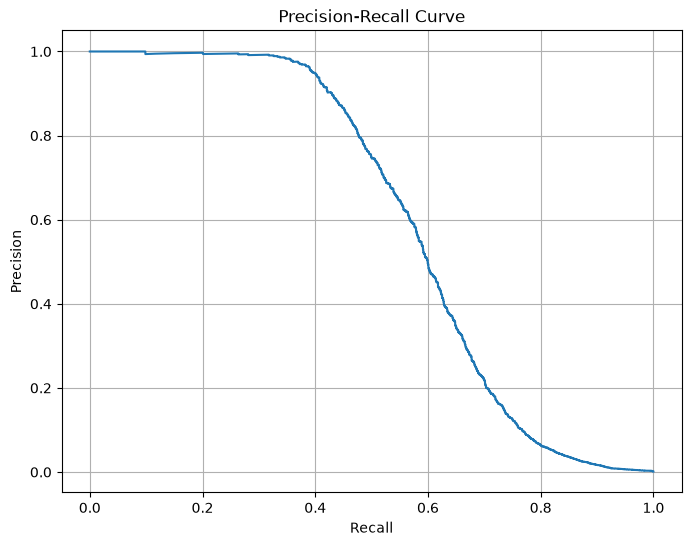

In [51]:
plt.figure(figsize=(8,6))

plt.plot(recall, precision)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.grid()

plt.show()

In [52]:
from sklearn.metrics import average_precision_score

ap = average_precision_score(y_test, fraud_proba)

print("Average Precision :", ap)

Average Precision : 0.5985009435599391


In [53]:
target_recall = 0.80

valid = recall[:-1] >= target_recall
candidate_indices = np.where(valid)[0]

best_idx = candidate_indices[-1]

print("Threshold :", thresholds[best_idx])
print("Precision :", precision[best_idx])
print("Recall :", recall[best_idx])

Threshold : 0.007002441635663129
Precision : 0.06353884808658677
Recall : 0.8003651856360317


In [55]:
threshold = 0.007002441635663129

y_pred_optimized = (fraud_proba >= threshold).astype(int)

cm = confusion_matrix(y_test, y_pred_optimized)

print(cm)
print(classification_report(y_test, y_pred_optimized))

[[1251500   19381]
 [    328    1315]]
              precision    recall  f1-score   support

           0       1.00      0.98      0.99   1270881
           1       0.06      0.80      0.12      1643

    accuracy                           0.98   1272524
   macro avg       0.53      0.89      0.55   1272524
weighted avg       1.00      0.98      0.99   1272524



In [69]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
print(cv)

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


In [60]:
for fold, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train), 1):
    print(f"Fold {fold}")
    print("Train :", len(train_idx))
    print("Validation :", len(val_idx))

Fold 1
Train : 4072076
Validation : 1018020
Fold 2
Train : 4072077
Validation : 1018019
Fold 3
Train : 4072077
Validation : 1018019
Fold 4
Train : 4072077
Validation : 1018019
Fold 5
Train : 4072077
Validation : 1018019


In [61]:
for fold, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train), 1):
    y_val = y_train.iloc[val_idx]

    print(
        f"Fold {fold} - "
        f"Fraudes : {y_val.sum()} - "
        f"Proportion : {y_val.mean():.6%}"
    )

Fold 1 - Fraudes : 1314 - Proportion : 0.129074%
Fold 2 - Fraudes : 1314 - Proportion : 0.129074%
Fold 3 - Fraudes : 1314 - Proportion : 0.129074%
Fold 4 - Fraudes : 1314 - Proportion : 0.129074%
Fold 5 - Fraudes : 1314 - Proportion : 0.129074%


In [63]:
help(cross_validate)

Help on function cross_validate in module sklearn.model_selection._validation:

cross_validate(estimator, X, y=None, *, groups=None, scoring=None, cv=None, n_jobs=None, verbose=0, params=None, pre_dispatch='2*n_jobs', return_train_score=False, return_estimator=False, return_indices=False, error_score=nan)
    Evaluate metric(s) by cross-validation and also record fit/score times.

    Read more in the :ref:`User Guide <multimetric_cross_validation>`.

    Parameters
    ----------
    estimator : estimator object implementing 'fit'
        The object to use to fit the data.

    X : {array-like, sparse matrix} of shape (n_samples, n_features)
        The data to fit. Can be for example a list, or an array.

    y : array-like of shape (n_samples,) or (n_samples, n_outputs), default=None
        The target variable to try to predict in the case of
        supervised learning.

    groups : array-like of shape (n_samples,), default=None
        Group labels for the samples used while spl

In [64]:
cv_results = cross_validate(
    pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

In [65]:
print(cv_results["test_score"])
print(cv_results["test_score"].mean())

[0.55537891 0.5641293  0.58755881 0.56329114 0.57398631]
0.5688688931308732


In [66]:
scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}
cv_results = cross_validate(
    pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)
print("Precision :", cv_results["test_precision"])
print("Recall    :", cv_results["test_recall"])
print("F1        :", cv_results["test_f1"])

print("\nMoyennes :")
print("Precision :", cv_results["test_precision"].mean())
print("Recall    :", cv_results["test_recall"].mean())
print("F1        :", cv_results["test_f1"].mean())

Precision : [0.91448517 0.89569536 0.93823038 0.91752577 0.93162393]
Recall    : [0.39878234 0.41171994 0.42770167 0.40639269 0.41476408]
F1        : [0.55537891 0.5641293  0.58755881 0.56329114 0.57398631]

Moyennes :
Precision : 0.9195121237651147
Recall    : 0.41187214611872147
F1        : 0.5688688931308732


In [68]:
pipeline_smote = ImbPipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

In [69]:
pipeline_smote.fit(X_train, y_train)
y_pred_smote = pipeline_smote.predict(X_test)

In [70]:
from sklearn.metrics import classification_report, confusion_matrix

print(confusion_matrix(y_test, y_pred_smote))
print(classification_report(y_test, y_pred_smote))

[[1205200   65681]
 [     60    1583]]
              precision    recall  f1-score   support

           0       1.00      0.95      0.97   1270881
           1       0.02      0.96      0.05      1643

    accuracy                           0.95   1272524
   macro avg       0.51      0.96      0.51   1272524
weighted avg       1.00      0.95      0.97   1272524



In [72]:
categorical_features = ["type"]

numerical_features = [
    "step",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]

In [73]:
from sklearn.preprocessing import OrdinalEncoder

preprocessor_smote = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OrdinalEncoder(), categorical_features)
    ]
)

In [76]:
X_train_smote = X_train.copy()
X_test_smote = X_test.copy()

encoder = OrdinalEncoder()

X_train_smote[["type"]] = encoder.fit_transform(
    X_train_smote[["type"]]
)

X_test_smote[["type"]] = encoder.transform(
    X_test_smote[["type"]]
)

In [77]:
categorical_indices = [X_train_smote.columns.get_loc("type")]

smotenc = SMOTENC(
    categorical_features=categorical_indices,
    random_state=42
)

In [78]:
X_train_resampled, y_train_resampled = smotenc.fit_resample(
    X_train_smote,
    y_train
)
print(X_train_resampled.shape)
print(y_train_resampled.value_counts())

(10167052, 7)
isFraud
0    5083526
1    5083526
Name: count, dtype: int64


In [79]:
preprocessor_final = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(drop="first"), categorical_features)
    ]
)
X_train_resampled_transformed = preprocessor_final.fit_transform(
    X_train_resampled
)

X_test_transformed = preprocessor_final.transform(
    X_test_smote
)
model_smotenc = LogisticRegression(max_iter=1000)

model_smotenc.fit(
    X_train_resampled_transformed,
    y_train_resampled
)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [80]:
y_pred_smotenc = model_smotenc.predict(X_test_transformed)
print(confusion_matrix(y_test, y_pred_smotenc))
print(classification_report(y_test, y_pred_smotenc))

[[1207826   63055]
 [     68    1575]]
              precision    recall  f1-score   support

           0       1.00      0.95      0.97   1270881
           1       0.02      0.96      0.05      1643

    accuracy                           0.95   1272524
   macro avg       0.51      0.95      0.51   1272524
weighted avg       1.00      0.95      0.97   1272524



In [82]:
pipeline_tree = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            random_state=42
        ))
    ]
)
pipeline_tree.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['step','type','amount',...,'newbalanceOrig','oldbalanceDest', 'newbalanceDest']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('scaler', ...), ('encoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='p

In [83]:
y_pred_tree = pipeline_tree.predict(X_test)

print(confusion_matrix(y_test, y_pred_tree))
print(classification_report(y_test, y_pred_tree))

[[1270699     182]
 [    198    1445]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.89      0.88      0.88      1643

    accuracy                           1.00   1272524
   macro avg       0.94      0.94      0.94   1272524
weighted avg       1.00      1.00      1.00   1272524



In [84]:
for depth in [5, 10, 15]:
    pipeline_tree_test = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", DecisionTreeClassifier(
                max_depth=depth,
                random_state=42
            ))
        ]
    )

    pipeline_tree_test.fit(X_train, y_train)

    y_pred = pipeline_tree_test.predict(X_test)

    print(f"\n===== max_depth = {depth} =====")
    print(classification_report(y_test, y_pred))


===== max_depth = 5 =====
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.78      0.72      0.75      1643

    accuracy                           1.00   1272524
   macro avg       0.89      0.86      0.87   1272524
weighted avg       1.00      1.00      1.00   1272524


===== max_depth = 10 =====
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.96      0.75      0.84      1643

    accuracy                           1.00   1272524
   macro avg       0.98      0.88      0.92   1272524
weighted avg       1.00      1.00      1.00   1272524


===== max_depth = 15 =====
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.94      0.79      0.86      1643

    accuracy                           1.00   1272524
   macro avg       0.97      0.90      0.93  

In [85]:
pipeline_tree_10 = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=10,
            random_state=42
        ))
    ]
)
cv_tree = cross_validate(
    pipeline_tree_10,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "precision": "precision",
        "recall": "recall",
        "f1": "f1"
    },
    n_jobs=-1
)

In [86]:
print("Precision :", cv_tree["test_precision"])
print("Recall    :", cv_tree["test_recall"])
print("F1        :", cv_tree["test_f1"])

print("\nMoyennes :")
print("Precision :", cv_tree["test_precision"].mean())
print("Recall    :", cv_tree["test_recall"].mean())
print("F1        :", cv_tree["test_f1"].mean())

Precision : [0.97053045 0.97761953 0.96608527 0.97484909 0.98720682]
Recall    : [0.75190259 0.73135464 0.7587519  0.73744292 0.70471842]
F1        : [0.84734134 0.83674358 0.84995737 0.83968804 0.82238011]

Moyennes :
Precision : 0.9752582345648237
Recall    : 0.7368340943683409
F1        : 0.8392220877817145


In [87]:
param_grid = {
    "classifier__max_depth": [5, 10, 15],
    "classifier__min_samples_split": [2, 10, 50],
    "classifier__min_samples_leaf": [1, 5, 20]
}


In [89]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    estimator=pipeline_tree_10,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 27 candidates, totalling 135 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__max_depth': [5, 10, ...], 'classifier__min_samples_leaf': [1, 5, ...], 'classifier__min_samples_split': [2, 10, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metriceval

In [90]:
print("Meilleurs paramètres :")
print(grid_search.best_params_)

print("\nMeilleur F1 CV :")
print(grid_search.best_score_)

Meilleurs paramètres :
{'classifier__max_depth': 15, 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 2}

Meilleur F1 CV :
0.859828744821252


In [91]:
best_tree = grid_search.best_estimator_

y_pred_best = best_tree.predict(X_test)

print(confusion_matrix(y_test, y_pred_best))
print(classification_report(y_test, y_pred_best))

[[1270796      85]
 [    349    1294]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.94      0.79      0.86      1643

    accuracy                           1.00   1272524
   macro avg       0.97      0.89      0.93   1272524
weighted avg       1.00      1.00      1.00   1272524



In [96]:
pipeline_rf = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=50,
            random_state=42,
            n_jobs=-1
        ))
    ]
)
pipeline_rf.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['step','type','amount',...,'newbalanceOrig','oldbalanceDest', 'newbalanceDest']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('scaler', ...), ('encoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='p

In [97]:
y_pred_rf = pipeline_rf.predict(X_test)
print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

[[1270848      33]
 [    353    1290]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.98      0.79      0.87      1643

    accuracy                           1.00   1272524
   macro avg       0.99      0.89      0.93   1272524
weighted avg       1.00      1.00      1.00   1272524



In [98]:
cv_rf = cross_validate(
    pipeline_rf,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "precision": "precision",
        "recall": "recall",
        "f1": "f1"
    },
    n_jobs=-1
)

print("Precision :", cv_rf["test_precision"])
print("Precision moyenne :", cv_rf["test_precision"].mean())

print("Recall :", cv_rf["test_recall"])
print("Recall moyenne :", cv_rf["test_recall"].mean())

print("F1 :", cv_rf["test_f1"])
print("F1 moyenne :", cv_rf["test_f1"].mean())

Precision : [0.98376313 0.98360656 0.97922568 0.98510242 0.97701149]
Precision moyenne : 0.9817418579709845
Recall : [0.78386606 0.77625571 0.7891933  0.80517504 0.77625571]
Recall moyenne : 0.7861491628614916
F1 : [0.87251165 0.86771587 0.87399916 0.88609715 0.86513995]
F1 moyenne : 0.8730927543838561


In [100]:
X_train_small, _, y_train_small, _ = train_test_split(
    X_train,
    y_train,
    train_size=500_000,
    random_state=42,
    stratify=y_train
)

print(X_train_small.shape)
print(y_train_small.value_counts())
param_grid_rf = {
    "classifier__n_estimators": [50, 100],
    "classifier__max_depth": [10, 15],
    "classifier__min_samples_leaf": [1, 5]
}
grid_search_rf = GridSearchCV(
    estimator=pipeline_rf,
    param_grid=param_grid_rf,
    scoring="f1",
    cv=cv,
    n_jobs=2,
    verbose=1
)
grid_search_rf.fit(X_train_small, y_train_small)

(500000, 7)
isFraud
0    499355
1       645
Name: count, dtype: int64
Fitting 5 folds for each of 8 candidates, totalling 40 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__max_depth': [10, 15], 'classifier__min_samples_leaf': [1, 5], 'classifier__n_estimators': [50, 100]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",2
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`s

In [101]:
print("Best parameters:")
print(grid_search_rf.best_params_)

print("\nBest CV F1:")
print(grid_search_rf.best_score_)

Best parameters:
{'classifier__max_depth': 15, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 100}

Best CV F1:
0.8526858925897365


In [37]:
rf_final = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            max_depth=15,
            min_samples_leaf=1,
            random_state=42,
            n_jobs=-1
        ))
    ]
)
rf_final.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['step','type','amount',...,'newbalanceOrig','oldbalanceDest', 'newbalanceDest']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('scaler', ...), ('encoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='p

In [40]:
y_pred_rf_final = rf_final.predict(X_test)
print(confusion_matrix(y_test, y_pred_rf_final))
print(classification_report(y_test, y_pred_rf_final))

[[1270862      19]
 [    400    1243]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.98      0.76      0.86      1643

    accuracy                           1.00   1272524
   macro avg       0.99      0.88      0.93   1272524
weighted avg       1.00      1.00      1.00   1272524



FEATURES IMPORTANCES & SHAP

In [41]:
feature_importances = rf_final.named_steps["classifier"].feature_importances_
feature_names = rf_final.named_steps["preprocessor"].get_feature_names_out()

In [42]:
importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": feature_importances
})

importance_df = importance_df.sort_values(
    by="importance",
    ascending=False
)

importance_df

,feature,importance
5,scaler__newbalanceDest,0.328120
2,scaler__oldbalanceOrg,0.254040
1,scaler__amount,0.140596
0,scaler__step,0.080657
4,scaler__oldbalanceDest,0.061141
9,encoder__type_TRANSFER,0.060444
3,scaler__newbalanceOrig,0.037293
6,encoder__type_CASH_OUT,0.036262
8,encoder__type_PAYMENT,0.001395
7,encoder__type_DEBIT,0.000052


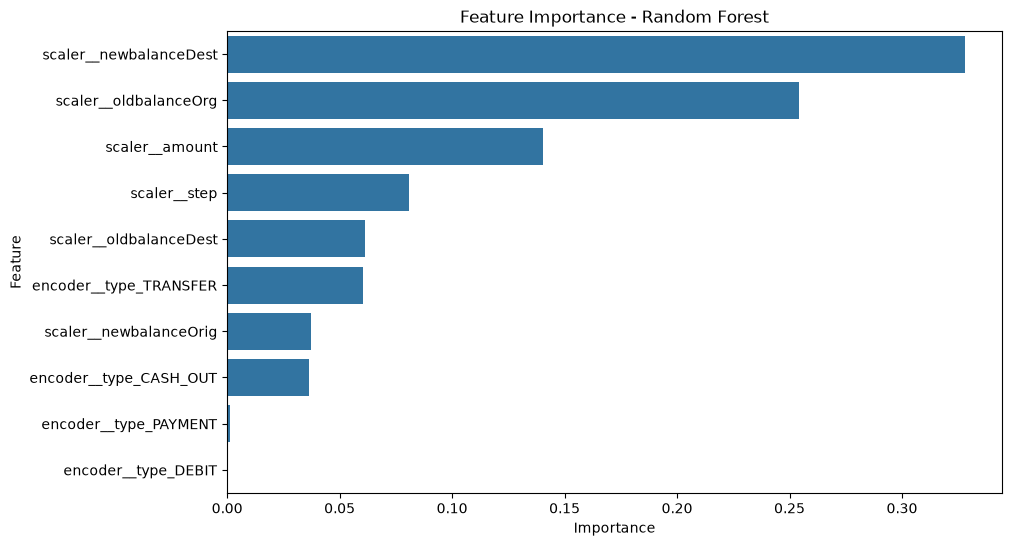

In [43]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="importance",
    y="feature"
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

In [44]:
X_shap = X_test.sample(
    n=1000,
    random_state=42
)
y_shap = y_test.loc[X_shap.index]

In [45]:
X_shap_transformed = rf_final.named_steps["preprocessor"].transform(X_shap)
feature_names = rf_final.named_steps[
    "preprocessor"
].get_feature_names_out()

In [50]:
explainer = shap.TreeExplainer(
    rf_final.named_steps["classifier"]
)
shap_values = explainer.shap_values(X_shap_transformed)
shap_values_fraud = shap_values[:, :, 1]


In [49]:
print("X_shap_transformed :", X_shap_transformed.shape)
print("shap_values        :", shap_values.shape)
print("feature_names      :", len(feature_names))

X_shap_transformed : (1000, 10)
shap_values        : (1000, 10, 2)
feature_names      : 10


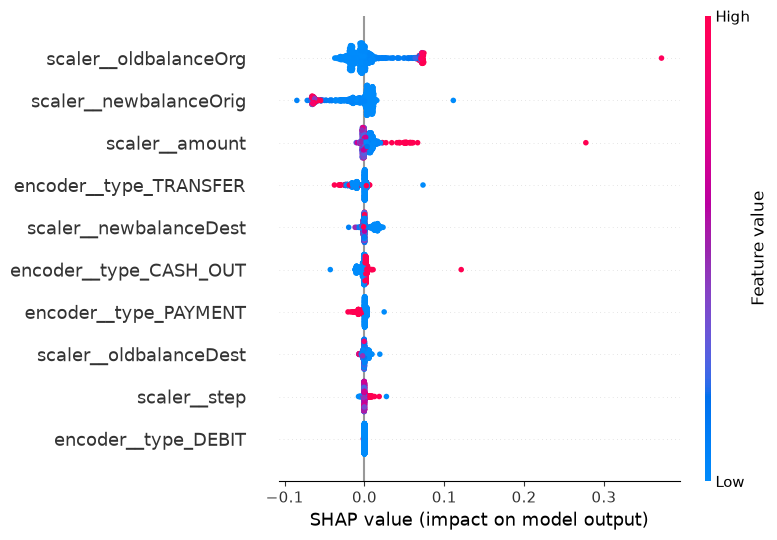

In [51]:
shap.summary_plot(
    shap_values_fraud,
    X_shap_transformed,
    feature_names=feature_names
)

In [52]:
fraud_indices = y_shap[y_shap == 1].index

X_one = X_shap.loc[[fraud_indices[0]]]
print(X_one)

         step      type      amount  oldbalanceOrg  newbalanceOrig  \
6020257   461  CASH_OUT  6273660.45     6273660.45             0.0   

         oldbalanceDest  newbalanceDest  
6020257       763912.31      7037572.76  


In [54]:
X_one_transformed = rf_final.named_steps[
    "preprocessor"
].transform(X_one)
shap_one = explainer.shap_values(X_one_transformed)
shap_one_fraud = shap_one[0, :, 1]
explanation_df = pd.DataFrame({
    "feature": feature_names,
    "shap_value": shap_one_fraud
})

explanation_df = pd.DataFrame({
    "feature": feature_names,
    "shap_value": shap_one_fraud
})

explanation_df = explanation_df.sort_values(
    "shap_value",
    key=abs,
    ascending=False
)

explanation_df


,feature,shap_value
2,scaler__oldbalanceOrg,0.372112
1,scaler__amount,0.277331
6,encoder__type_CASH_OUT,0.121183
3,scaler__newbalanceOrig,0.111320
9,encoder__type_TRANSFER,0.073319
8,encoder__type_PAYMENT,0.024681
0,scaler__step,0.018455
5,scaler__newbalanceDest,0.004141
4,scaler__oldbalanceDest,-0.003839
7,encoder__type_DEBIT,0.000007


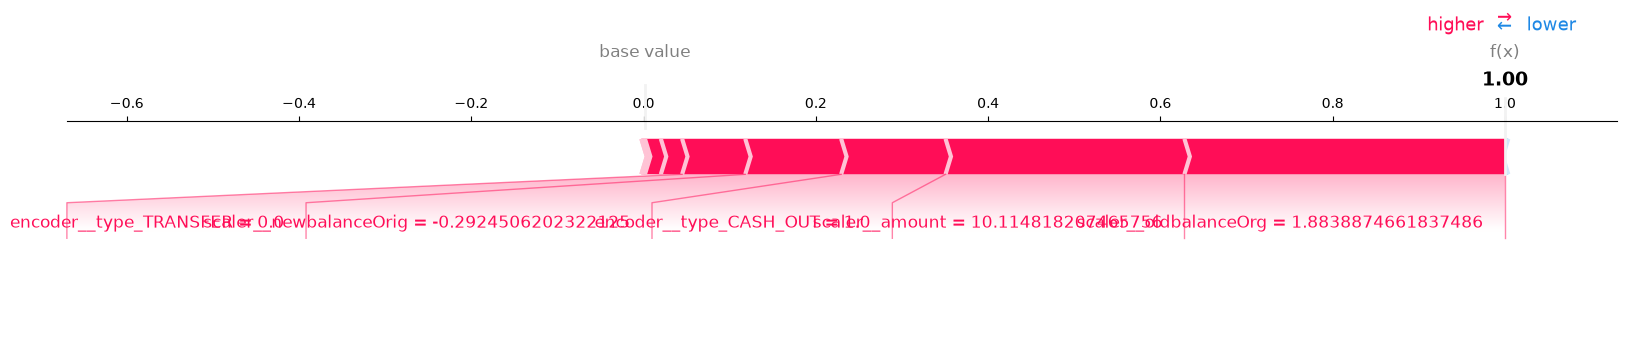

In [56]:
shap.force_plot(
    explainer.expected_value[1],
    shap_one[0, :, 1],
    X_one_transformed[0],
    feature_names=feature_names,
    matplotlib=True
)

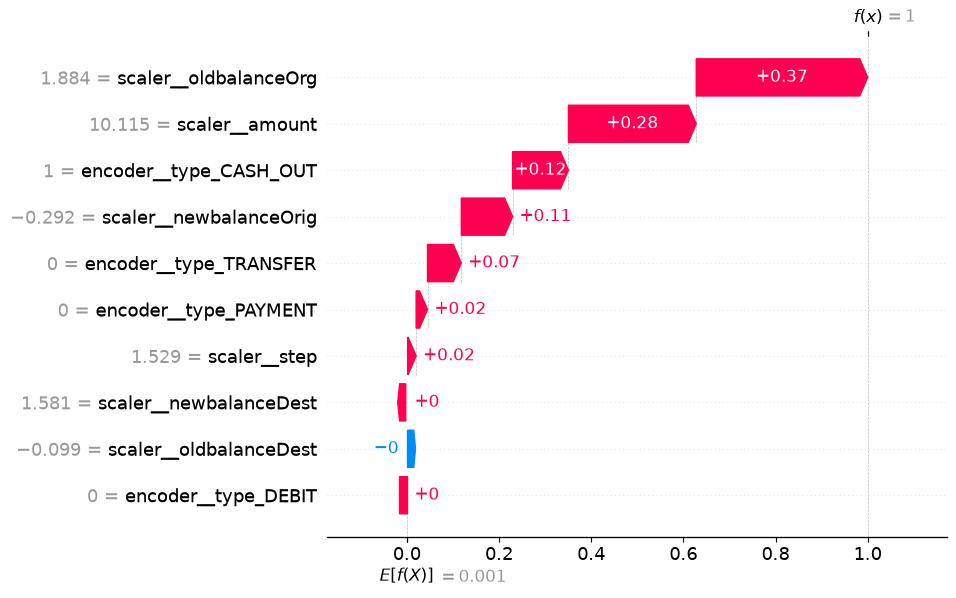

In [57]:
shap.waterfall_plot(
    shap.Explanation(
        values=shap_one_fraud,
        base_values=explainer.expected_value[1],
        data=X_one_transformed[0],
        feature_names=feature_names
    )
)


In [58]:
X_fraud = X_test[y_test == 1].sample(
    n=500,
    random_state=42
)

X_normal = X_test[y_test == 0].sample(
    n=500,
    random_state=42
)
X_fraud_transformed = rf_final.named_steps[
    "preprocessor"
].transform(X_fraud)

X_normal_transformed = rf_final.named_steps[
    "preprocessor"
].transform(X_normal)

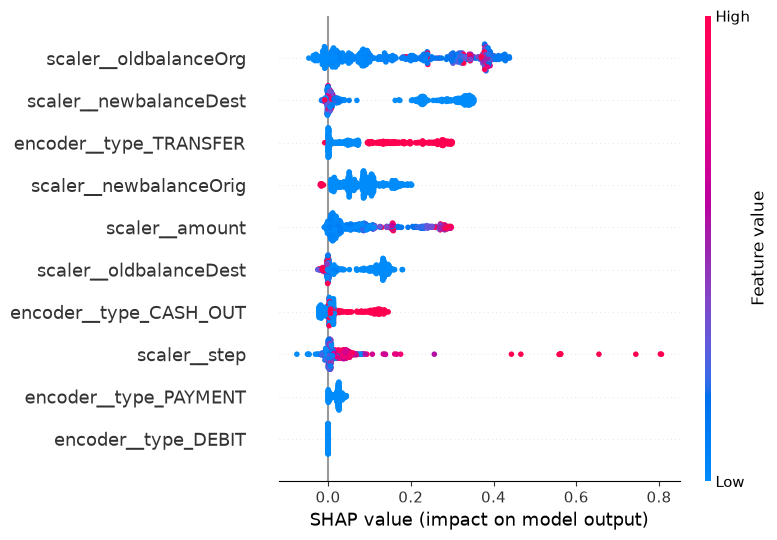

In [59]:
shap_fraud = explainer.shap_values(X_fraud_transformed)
shap_normal = explainer.shap_values(X_normal_transformed)
shap_fraud_class1 = shap_fraud[:, :, 1]
shap_normal_class1 = shap_normal[:, :, 1]
shap.summary_plot(
    shap_fraud_class1,
    X_fraud_transformed,
    feature_names=feature_names,
    show=True
)

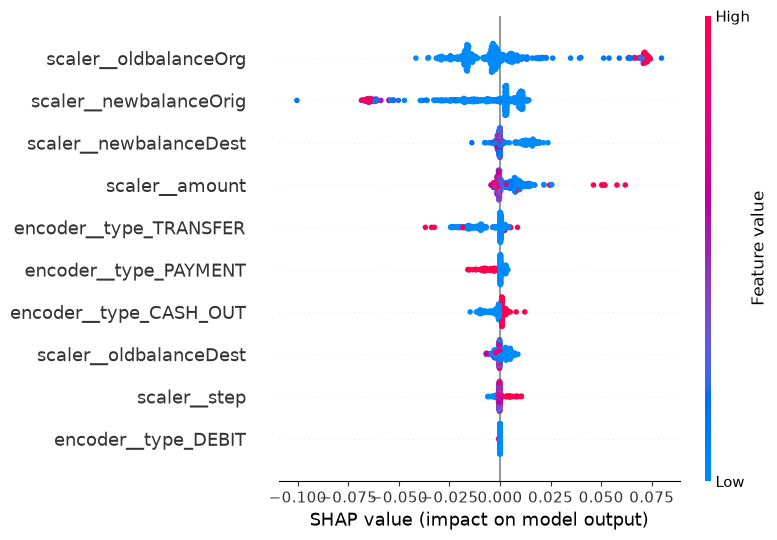

In [60]:
shap.summary_plot(
    shap_normal_class1,
    X_normal_transformed,
    feature_names=feature_names,
    show=True
)

In [61]:
fraud_importance = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap_fraud": np.abs(shap_fraud_class1).mean(axis=0)
})

fraud_importance = fraud_importance.sort_values(
    "mean_abs_shap_fraud",
    ascending=False
)

fraud_importance


,feature,mean_abs_shap_fraud
2,scaler__oldbalanceOrg,0.180808
5,scaler__newbalanceDest,0.156590
9,encoder__type_TRANSFER,0.122854
3,scaler__newbalanceOrig,0.081123
1,scaler__amount,0.078899
4,scaler__oldbalanceDest,0.070798
6,encoder__type_CASH_OUT,0.035575
0,scaler__step,0.034398
8,encoder__type_PAYMENT,0.020932
7,encoder__type_DEBIT,0.000021


In [62]:
normal_importance = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap_normal": np.abs(shap_normal_class1).mean(axis=0)
})

normal_importance = normal_importance.sort_values(
    "mean_abs_shap_normal",
    ascending=False
)

normal_importance

,feature,mean_abs_shap_normal
2,scaler__oldbalanceOrg,0.016933
3,scaler__newbalanceOrig,0.015547
5,scaler__newbalanceDest,0.006055
1,scaler__amount,0.005964
9,encoder__type_TRANSFER,0.005887
8,encoder__type_PAYMENT,0.002579
6,encoder__type_CASH_OUT,0.002508
4,scaler__oldbalanceDest,0.002265
0,scaler__step,0.000843
7,encoder__type_DEBIT,0.000006


In [63]:
shap_comparison = fraud_importance.merge(
    normal_importance,
    on="feature"
)

shap_comparison

,feature,mean_abs_shap_fraud,mean_abs_shap_normal
0,scaler__oldbalanceOrg,0.180808,0.016933
1,scaler__newbalanceDest,0.156590,0.006055
2,encoder__type_TRANSFER,0.122854,0.005887
3,scaler__newbalanceOrig,0.081123,0.015547
4,scaler__amount,0.078899,0.005964
5,scaler__oldbalanceDest,0.070798,0.002265
6,encoder__type_CASH_OUT,0.035575,0.002508
7,scaler__step,0.034398,0.000843
8,encoder__type_PAYMENT,0.020932,0.002579
9,encoder__type_DEBIT,0.000021,0.000006


In [64]:
shap_comparison = shap_comparison.sort_values(
    "mean_abs_shap_fraud",
    ascending=False
)

shap_comparison

,feature,mean_abs_shap_fraud,mean_abs_shap_normal
0,scaler__oldbalanceOrg,0.180808,0.016933
1,scaler__newbalanceDest,0.156590,0.006055
2,encoder__type_TRANSFER,0.122854,0.005887
3,scaler__newbalanceOrig,0.081123,0.015547
4,scaler__amount,0.078899,0.005964
5,scaler__oldbalanceDest,0.070798,0.002265
6,encoder__type_CASH_OUT,0.035575,0.002508
7,scaler__step,0.034398,0.000843
8,encoder__type_PAYMENT,0.020932,0.002579
9,encoder__type_DEBIT,0.000021,0.000006


XG BOOST

In [66]:


pipeline_xgb = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=100,
            max_depth=6,
            learning_rate=0.1,
            random_state=42,
            n_jobs=2,
            eval_metric="logloss"
        ))
    ]
)
pipeline_xgb.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['step','type','amount',...,'newbalanceOrig','oldbalanceDest', 'newbalanceDest']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('scaler', ...), ('encoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='p

In [67]:
y_pred_xgb = pipeline_xgb.predict(X_test)
print(confusion_matrix(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))

[[1270846      35]
 [    281    1362]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.97      0.83      0.90      1643

    accuracy                           1.00   1272524
   macro avg       0.99      0.91      0.95   1272524
weighted avg       1.00      1.00      1.00   1272524



In [70]:
cv_xgb = cross_validate(
    pipeline_xgb,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "precision": "precision",
        "recall": "recall",
        "f1": "f1"
    },
    n_jobs=2
)

print("Precision :", cv_xgb["test_precision"])
print("Precision moyenne :", cv_xgb["test_precision"].mean())

print("Recall :", cv_xgb["test_recall"])
print("Recall moyenne :", cv_xgb["test_recall"].mean())

print("F1 :", cv_xgb["test_f1"])
print("F1 moyenne :", cv_xgb["test_f1"].mean())

Precision : [0.97506925 0.9652333  0.978957   0.967713   0.95577617]
Precision moyenne : 0.9685497463536767
Recall : [0.80365297 0.80289193 0.81430746 0.82115677 0.80593607]
Recall moyenne : 0.8095890410958905
F1 : [0.88110138 0.87660989 0.88907354 0.88843145 0.8744839 ]
F1 moyenne : 0.881940030189541


In [73]:
X_train_small, _, y_train_small, _ = train_test_split(
    X_train,
    y_train,
    train_size=500_000,
    random_state=42,
    stratify=y_train
)
param_grid_xgb = {
    "classifier__max_depth": [4, 6],
    "classifier__learning_rate": [0.05, 0.1],
    "classifier__n_estimators": [100, 200]
}
grid_search_xgb = GridSearchCV(
    estimator=pipeline_xgb,
    param_grid=param_grid_xgb,
    scoring="f1",
    cv=cv,
    n_jobs=2,
    verbose=1
)

grid_search_xgb.fit(
    X_train_small,
    y_train_small
)
print("Best parameters:")
print(grid_search_xgb.best_params_)

print("\nBest CV F1:")
print(grid_search_xgb.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best parameters:
{'classifier__learning_rate': 0.05, 'classifier__max_depth': 6, 'classifier__n_estimators': 200}

Best CV F1:
0.8670977397541616


In [74]:
best_xgb = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            learning_rate=0.05,
            max_depth=6,
            n_estimators=200,
            random_state=42,
            n_jobs=2,
            eval_metric="logloss"
        ))
    ]
)
best_xgb.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['step','type','amount',...,'newbalanceOrig','oldbalanceDest', 'newbalanceDest']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('scaler', ...), ('encoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='p

In [75]:
y_pred_best_xgb = best_xgb.predict(X_test)

print(confusion_matrix(y_test, y_pred_best_xgb))
print(classification_report(y_test, y_pred_best_xgb))

[[1270840      41]
 [    290    1353]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.97      0.82      0.89      1643

    accuracy                           1.00   1272524
   macro avg       0.99      0.91      0.95   1272524
weighted avg       1.00      1.00      1.00   1272524



In [76]:
y_proba_xgb = pipeline_xgb.predict_proba(X_test)[:, 1]

In [79]:
precision_xgb, recall_xgb, thresholds_xgb = precision_recall_curve(
    y_test,
    y_proba_xgb
)

In [80]:
f1_xgb = (
    2 * precision_xgb[:-1] * recall_xgb[:-1]
    / (precision_xgb[:-1] + recall_xgb[:-1] + 1e-10)
)

best_idx = np.argmax(f1_xgb)

print("Best threshold :", thresholds_xgb[best_idx])
print("Precision :", precision_xgb[best_idx])
print("Recall :", recall_xgb[best_idx])
print("F1 :", f1_xgb[best_idx])

Best threshold : 0.30337518
Precision : 0.9261400128452152
Recall : 0.8776628119293974
F1 : 0.9012499999500361


In [83]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

y_proba_oof = cross_val_predict(
    pipeline_xgb,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=2
)[:, 1]

print(y_proba_oof[:10])


[1.1798325e-06 3.0602234e-06 4.2202651e-06 3.1381558e-06 4.9046694e-06
 8.0840636e-07 3.9108509e-06 6.5874593e-07 5.1171878e-06 2.4847538e-06]


In [84]:
precision_oof, recall_oof, thresholds_oof = precision_recall_curve(
    y_train,
    y_proba_oof
)

f1_oof = (
    2 * precision_oof[:-1] * recall_oof[:-1]
    / (precision_oof[:-1] + recall_oof[:-1] + 1e-10)
)

best_idx = np.argmax(f1_oof)

best_threshold = thresholds_oof[best_idx]

print("Best threshold :", best_threshold)
print("Precision :", precision_oof[best_idx])
print("Recall :", recall_oof[best_idx])
print("F1 :", f1_oof[best_idx])

Best threshold : 0.33956692
Precision : 0.9365715239525956
Recall : 0.8540334855403349
F1 : 0.8934002069399956


In [89]:
y_proba_test = pipeline_xgb.predict_proba(X_test)[:, 1]

threshold_final = 0.33956692

y_pred_final = (
    y_proba_test >= threshold_final
).astype(int)
cm = confusion_matrix(y_test, y_pred_final)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))

print("Precision :", precision_score(y_test, y_pred_final))
print("Recall    :", recall_score(y_test, y_pred_final))
print("F1-score  :", f1_score(y_test, y_pred_final))

Confusion Matrix:
[[1270779     102]
 [    217    1426]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.93      0.87      0.90      1643

    accuracy                           1.00   1272524
   macro avg       0.97      0.93      0.95   1272524
weighted avg       1.00      1.00      1.00   1272524

Precision : 0.9332460732984293
Recall    : 0.8679245283018868
F1-score  : 0.8994008199306213


In [ ]:
explainer_xgb = shap.TreeExplainer(
    pipeline_xgb.named_steps["classifier"]
)
X_test_transformed = pipeline_xgb.named_steps["preprocessor"].transform(X_test)

feature_names = (
    pipeline_xgb
    .named_steps["preprocessor"]
    .get_feature_names_out()
)
X_shap = X_test.sample(
    n=1000,
    random_state=42
)

X_shap_transformed = (
    pipeline_xgb
    .named_steps["preprocessor"]
    .transform(X_shap)
)
shap_values = explainer_xgb.shap_values(
    X_shap_transformed
)
print(shap_values.shape)

(1000, 10)
(1000, 10)


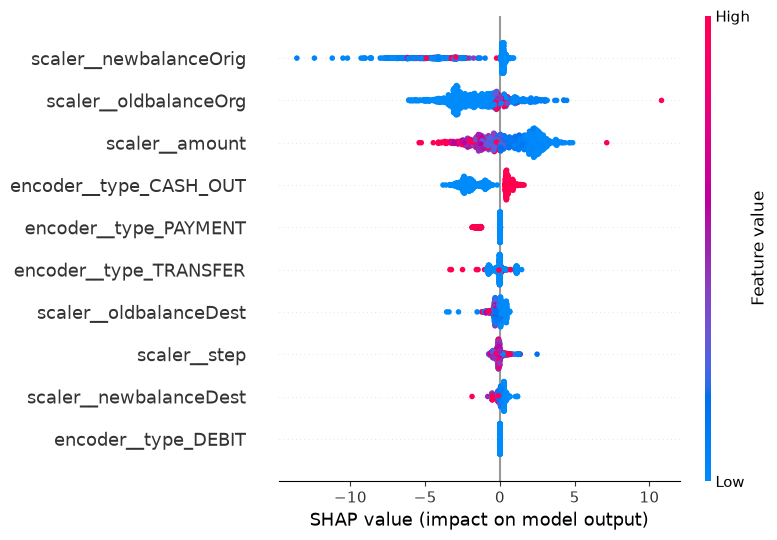

In [92]:
shap.summary_plot(
    shap_values,
    X_shap_transformed,
    feature_names=feature_names
)

In [93]:
shap_importance = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": abs(shap_values).mean(axis=0)
}).sort_values(
    "mean_abs_shap",
    ascending=False
)

print(shap_importance)

                  feature  mean_abs_shap
3  scaler__newbalanceOrig       2.081738
2   scaler__oldbalanceOrg       1.935472
1          scaler__amount       1.672903
6  encoder__type_CASH_OUT       1.490123
8   encoder__type_PAYMENT       0.483669
9  encoder__type_TRANSFER       0.336256
4  scaler__oldbalanceDest       0.250575
0            scaler__step       0.217877
5  scaler__newbalanceDest       0.212602
7     encoder__type_DEBIT       0.000000


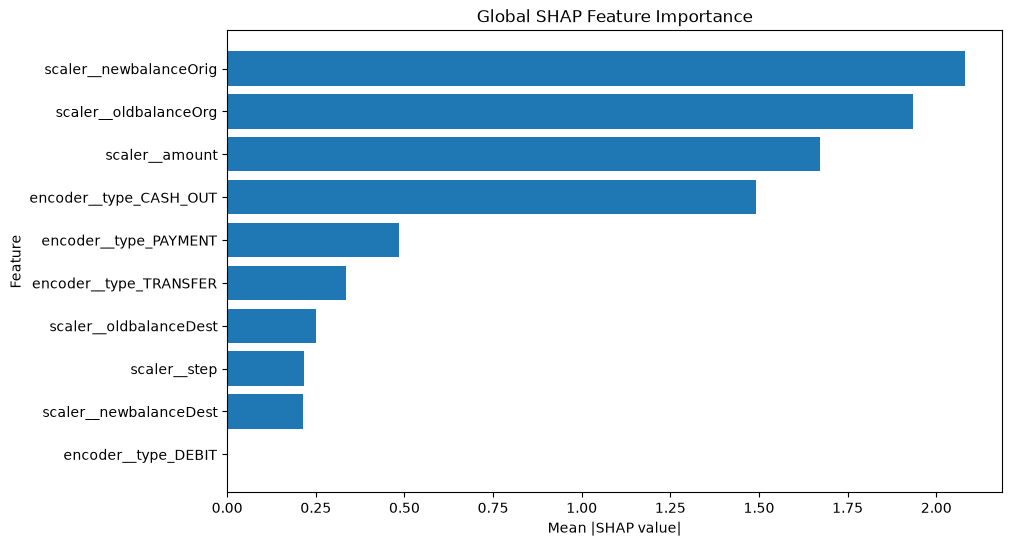

In [94]:
plt.figure(figsize=(10, 6))

plt.barh(
    shap_importance["feature"],
    shap_importance["mean_abs_shap"]
)

plt.xlabel("Mean |SHAP value|")
plt.ylabel("Feature")
plt.title("Global SHAP Feature Importance")

plt.gca().invert_yaxis()
plt.show()

Transaction :
         step      type     amount  oldbalanceOrg  newbalanceOrig  \
1220251   133  CASH_OUT  135627.66            0.0             0.0   

         oldbalanceDest  newbalanceDest  
1220251       196307.15       331934.82  

Probabilité de fraude :
1.19102815e-05


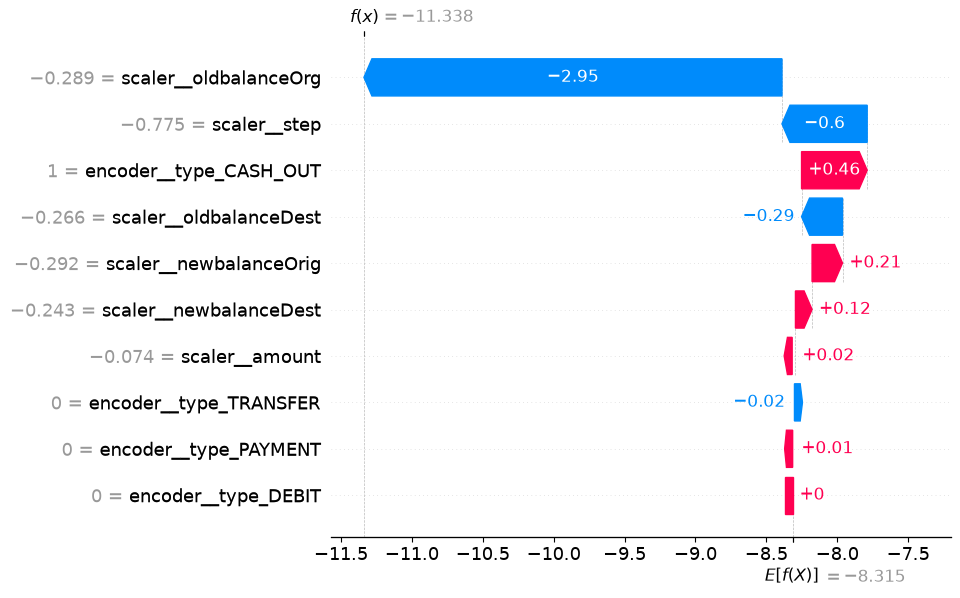

In [95]:
# Choisir une transaction
idx = 0

X_one = X_shap.iloc[[idx]]
X_one_transformed = X_shap_transformed[idx:idx+1]

shap_one = explainer_xgb.shap_values(X_one_transformed)

print("Transaction :")
print(X_one)

print("\nProbabilité de fraude :")
print(
    pipeline_xgb.predict_proba(X_one)[:, 1][0]
)
shap.plots.waterfall(
    shap.Explanation(
        values=shap_one[0],
        base_values=explainer_xgb.expected_value,
        data=X_one_transformed[0],
        feature_names=feature_names
    )
)

In [98]:
# Choisir une transaction
# Récupérer les index des transactions frauduleuses
fraud_indices = y_shap[y_shap == 1].index

# Prendre une seule transaction
fraud_idx = fraud_indices[0]

# Trouver sa position dans X_shap
pos = X_shap.index.get_loc(fraud_idx)

# Transaction originale
X_one = X_shap.loc[[fraud_idx]]

# Version transformée correspondante
X_one_transformed = X_shap_transformed[pos:pos+1]

# SHAP
shap_one = explainer_xgb.shap_values(X_one_transformed)

print("Transaction :")
print(X_one)

print("\nProbabilité de fraude :")
print(
    pipeline_xgb.predict_proba(X_one)[:, 1][0]
)

Transaction :
         step      type      amount  oldbalanceOrg  newbalanceOrig  \
6020257   461  CASH_OUT  6273660.45     6273660.45             0.0   

         oldbalanceDest  newbalanceDest  
6020257       763912.31      7037572.76  

Probabilité de fraude :
0.99999106


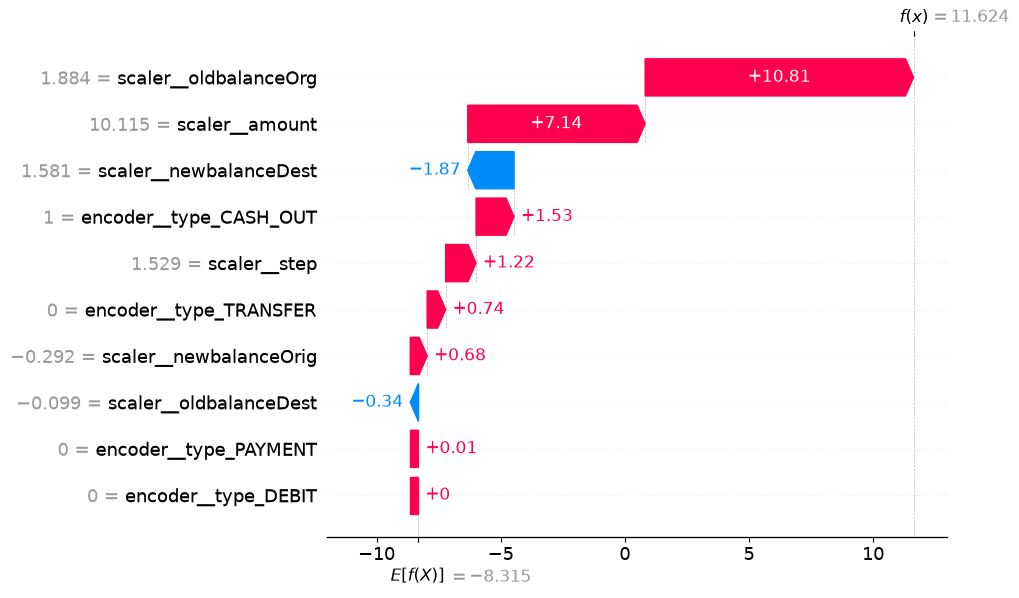

In [99]:
shap.plots.waterfall(
    shap.Explanation(
        values=shap_one[0],
        base_values=explainer_xgb.expected_value,
        data=X_one_transformed[0],
        feature_names=feature_names
    )
)

In [100]:
import joblib

model_artifact = {
    "model": pipeline_xgb,
    "threshold": 0.33956692
}

joblib.dump(
    model_artifact,
    "fraud_detection_xgb.pkl"
)

print("Modèle sauvegardé avec succès.")

Modèle sauvegardé avec succès.


In [101]:
import os

print(os.path.getsize("fraud_detection_xgb.pkl") / (1024**2), "MB")

0.2581462860107422 MB


In [102]:
artifact = joblib.load("fraud_detection_xgb.pkl")

loaded_model = artifact["model"]
threshold = artifact["threshold"]

print("Threshold :", threshold)
print("Model :", type(loaded_model))

Threshold : 0.33956692
Model : <class 'sklearn.pipeline.Pipeline'>


In [103]:
y_proba_loaded = loaded_model.predict_proba(X_test)[:, 1]

y_pred_loaded = (
    y_proba_loaded >= threshold
).astype(int)


In [104]:
print("Precision :", precision_score(y_test, y_pred_loaded))
print("Recall    :", recall_score(y_test, y_pred_loaded))
print("F1-score  :", f1_score(y_test, y_pred_loaded))

Precision : 0.9332460732984293
Recall    : 0.8679245283018868
F1-score  : 0.8994008199306213


In [109]:
artifact = joblib.load("fraud_detection_xgb.pkl")

model = artifact["model"]
threshold = artifact["threshold"]


def predict_fraud(
    step,
    type,
    amount,
    oldbalanceOrg,
    newbalanceOrig,
    oldbalanceDest,
    newbalanceDest
):
    
    transaction = pd.DataFrame([{
        "step": step,
        "type": type,
        "amount": amount,
        "oldbalanceOrg": oldbalanceOrg,
        "newbalanceOrig": newbalanceOrig,
        "oldbalanceDest": oldbalanceDest,
        "newbalanceDest": newbalanceDest
    }])
    
    probability = model.predict_proba(transaction)[0, 1]
    
    prediction = (
        "FRAUD"
        if probability >= threshold
        else "NORMAL"
    )
    
    return {
    "prediction": prediction,
    "probability": float(probability),
    "threshold": float(threshold)
}

In [110]:
result = predict_fraud(
    step=461,
    type="CASH_OUT",
    amount=6273660.45,
    oldbalanceOrg=6273660.45,
    newbalanceOrig=0,
    oldbalanceDest=763912.31,
    newbalanceDest=7037572.76
)

print(result)

{'prediction': 'FRAUD', 'probability': 0.9999910593032837, 'threshold': 0.33956692}
